# 26 · MjSpec: build and edit scenes in code, attach a gripper, randomize, save

In [1]:
import os, mujoco, mujoco_menagerie as mm, numpy as np, matplotlib.pyplot as plt

def snapshot(model, data, lookat=(0.4, 0, 0.3), distance=1.8, azimuth=150, elevation=-25, size=(360, 480)):
    with mujoco.Renderer(model, *size) as r:
        cam = mujoco.MjvCamera(); cam.lookat[:] = lookat
        cam.distance, cam.azimuth, cam.elevation = distance, azimuth, elevation
        r.update_scene(data, cam)
        return r.render()

def ur5e_with_robotiq():
    arm = mm.get("universal_robots_ur5e").spec("scene")
    gripper = mm.get("robotiq_2f85").spec("2f85")
    arm.option.cone, arm.option.impratio = gripper.option.cone, gripper.option.impratio
    arm.site("attachment_site").attach_body(gripper.worldbody.first_body(), "gripper_", "")
    return arm

def add_clutter(spec, n, rng):
    shapes = [mujoco.mjtGeom.mjGEOM_BOX, mujoco.mjtGeom.mjGEOM_SPHERE, mujoco.mjtGeom.mjGEOM_CYLINDER, mujoco.mjtGeom.mjGEOM_CAPSULE]
    for i in range(n):
        b = spec.worldbody.add_body(name=f"obj{i}", pos=[rng.uniform(0.3, 0.7), rng.uniform(-0.3, 0.3), 0.05 + 0.06 * i])
        b.add_freejoint()
        b.add_geom(type=shapes[i % 4], size=rng.uniform(0.015, 0.035, 3), rgba=np.r_[rng.uniform(0.2, 1, 3), 1],
                   mass=rng.uniform(0.05, 0.3))
    return spec

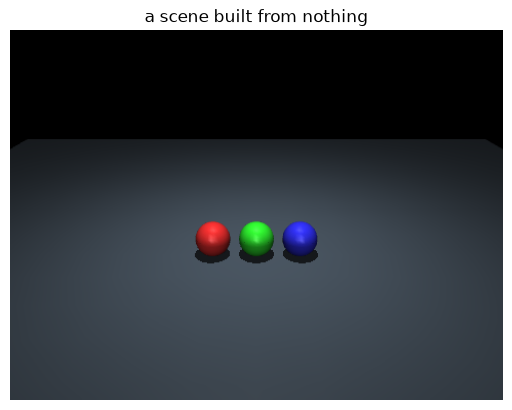

<mujoco model="MuJoCo Model">
  <compiler angle="radian"/>

  <worldbody>
    <geom size="2 2 0.1" type="plane" rgba="0.3 0.35 0.4 1"/>
    <light pos="0 0 3"/>
    <body name="ball0" pos="-0.2 0 0.5">
      <joint type="free"/>
      <geom size="0.08" rgba="1 0.2 0.2 1"/>
    </body>
    <body name="ball1" pos="0 0 0.8">
      <joint type="free"/>
      <geom size="0.08" rgba="0.2 1 0.2 1"/>
    </body>
    <body name="ball2" pos="0.2 0 1.1">
      <joint type="free"/>
      <geom size="0.08" rgba="0.2 0.2 1 1"/>
    </body>
  </worldbody>
</mujoco>



In [2]:
spec = mujoco.MjSpec()
spec.worldbody.add_light(pos=[0, 0, 3], dir=[0, 0, -1])
spec.worldbody.add_geom(type=mujoco.mjtGeom.mjGEOM_PLANE, size=[2, 2, 0.1], rgba=[0.3, 0.35, 0.4, 1])
for i, color in enumerate([[1, 0.2, 0.2, 1], [0.2, 1, 0.2, 1], [0.2, 0.2, 1, 1]]):
    b = spec.worldbody.add_body(name=f"ball{i}", pos=[0.2 * i - 0.2, 0, 0.5 + 0.3 * i])
    b.add_freejoint()
    b.add_geom(type=mujoco.mjtGeom.mjGEOM_SPHERE, size=[0.08, 0, 0], rgba=color)
model = spec.compile(); data = mujoco.MjData(model)
mujoco.mj_step(model, data, 600)
plt.imshow(snapshot(model, data, lookat=(0, 0, 0.2), distance=2.0, azimuth=90)); plt.axis("off"); plt.title("a scene built from nothing"); plt.show()
print(spec.to_xml()[:600])

actuators: ['shoulder_pan', 'shoulder_lift', 'elbow', 'wrist_1', 'wrist_2', 'wrist_3', 'gripper_fingers_actuator']


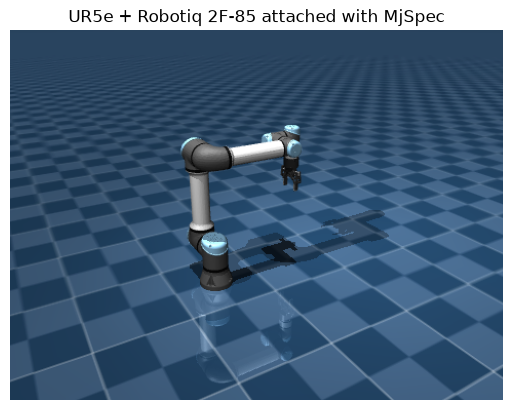

In [3]:
spec = ur5e_with_robotiq()
model = spec.compile(); data = mujoco.MjData(model)
mujoco.mj_resetDataKeyframe(model, data, 0); mujoco.mj_forward(model, data)
print("actuators:", [model.actuator(i).name for i in range(model.nu)])
plt.imshow(snapshot(model, data, lookat=(0.2, 0.1, 0.4))); plt.axis("off"); plt.title("UR5e + Robotiq 2F-85 attached with MjSpec"); plt.show()

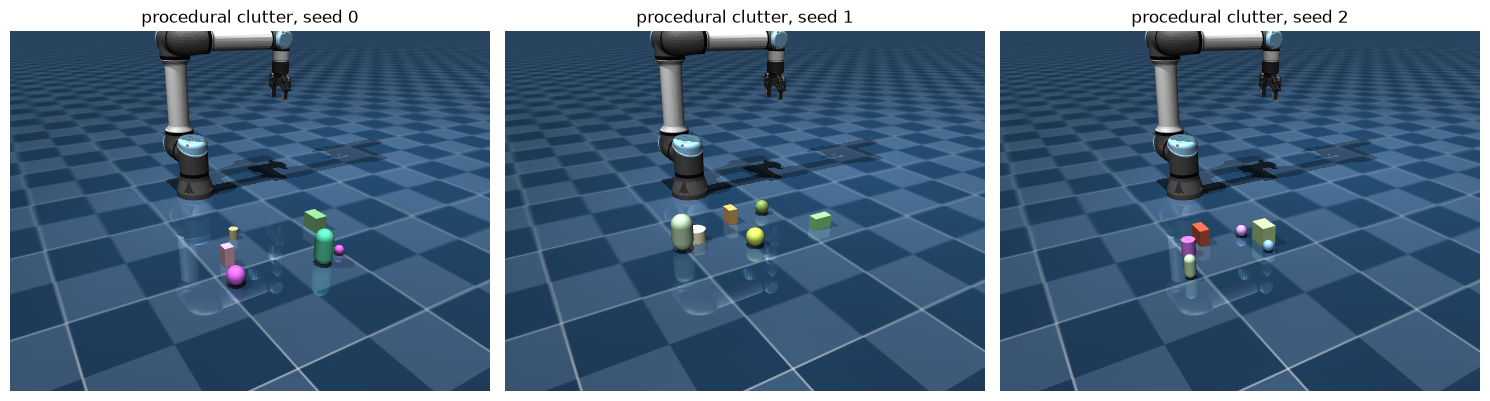

In [4]:
rng = np.random.default_rng(0)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, seed in zip(axes, [0, 1, 2]):
    rng = np.random.default_rng(seed)
    s = add_clutter(ur5e_with_robotiq(), 6, rng)
    m = s.compile(); d = mujoco.MjData(m)
    mujoco.mj_resetDataKeyframe(m, d, 0); mujoco.mj_step(m, d, 800)
    ax.imshow(snapshot(m, d, lookat=(0.45, 0, 0.1), distance=1.4)); ax.axis("off"); ax.set_title(f"procedural clutter, seed {seed}")
plt.tight_layout(); plt.show()

In [5]:
s = add_clutter(ur5e_with_robotiq(), 2, np.random.default_rng(5))
g = s.body("obj0").geoms[0]
g.rgba = [1, 1, 0, 1]
g.mass = 1.0
s.delete(s.body("obj1"))
print("objects left:", [b.name for b in s.bodies if b.name.startswith("obj")], "| obj0 mass:", s.body("obj0").geoms[0].mass)
os.makedirs("generated", exist_ok=True)
xml_path = "generated/ur5e_robotiq_clutter.xml"
open(xml_path, "w").write(s.to_xml())
print("saved", xml_path, "|", len(s.to_xml().splitlines()), "lines of MJCF")

objects left: ['obj0'] | obj0 mass: 1.0
saved generated/ur5e_robotiq_clutter.xml | 294 lines of MJCF
